# 02: The band-power baseline, Week 2 on FatigueSet

This notebook is the front door to the Week 2 analysis. The engine is the frozen pipeline in `src/`; nothing here retrains the study. I load the stored summary tables, rebuild the headline numbers from them, and run exactly one fold live through the frozen code so the path from windows to score is visible end to end.

Week 2 asked the first honest question of the project: with the label rules locked in advance and every fitting step kept inside the training folds, does a classical band-power model separate alert from fatigued windows at all, and how does the answer change as the evaluation gets more honest?

## 0. Setup

In [1]:
# Setup. The pipeline in src/ is the engine; this notebook is a front door
# to it. Here I find the repository root, put the frozen modules and the
# pinned libraries on the path, and patch one NumPy rename.
import sys
from pathlib import Path

import numpy as np
import pandas as pd

if not hasattr(np, "trapz"):
    # NumPy 2.x renamed trapz to trapezoid. The frozen band-power module
    # still calls np.trapz, so I alias it here instead of editing frozen code.
    np.trapz = np.trapezoid


def find_root(start=None):
    p = Path(start or Path.cwd()).resolve()
    for cand in [p, *p.parents]:
        if (cand / "src" / "features" / "bandpower.py").exists():
            return cand
    raise FileNotFoundError("repository root not found above the working directory")


ROOT = find_root()
for extra in (str(ROOT), str(Path.home() / "workspace" / ".pylibs")):
    if Path(extra).exists() and extra not in sys.path:
        sys.path.insert(0, extra)

TAB = ROOT / "results" / "tables"
FIG = ROOT / "results" / "figures"
PROC = ROOT / "data" / "processed"
pd.set_option("display.width", 120)
print("repository root:", ROOT)

repository root: /home/hatch/workspace/thesis-fatigue


## 1. The design in brief

- **Windows.** Each session is cut into 4-second non-overlapping windows at 128 Hz. A window takes its label from the block it falls in: M1 (early, before the treadmill block) is alert, M3 (late, after it) is fatigued.
- **Labels.** The primary labels are subjective. A session enters the primary set only if the participant's subjective fatigue rating rose from M1 to M3; the rule was locked before any training (`docs/label_rules.md`). 32 of the 36 sessions qualify; the other four are kept as a drift and sensitivity check set.
- **Amendment 1 masking.** The first version of the artefact rule rejected a window if any channel failed the checks, and it kept only 12.7% of candidate windows. The amended rule, also written down before results were seen, keeps a window if both frontal channels (AF7, AF8) pass the amplitude and flatline checks. A temporal channel that fails is masked for that window and carried as a validity indicator, never silently replaced with zeros.
- **Features.** 43 per window: log and relative band power (delta, theta, alpha, beta) for the four Muse channels, frontal and temporal band ratios, and the three masking indicators. Masked values are NaN and are imputed with training-fold medians only.
- **Model.** Logistic regression, L2, C = 1.0, class weights balanced. Imputation, scaling and class weights are all fitted inside the training fold (one sklearn Pipeline per fold), so nothing about the test windows leaks into fitting.
- **Class balance.** Inside each session, the larger M1 class is capped down to the retained M3 count. The cap subsample is the only random step in the baseline, so I run cap seeds 0 to 4 and average.
- **Evaluation levels, loosest to strictest.** Within-session (train and test inside one session, kept only as a separability reference), within-subject (rotate the held-out session of the same participant), leave-one-session-out pooled across participants, and leave-one-participant-out (LOPO), where the test participant contributes nothing to fitting.

In [2]:
retention = pd.read_csv(TAB / "retention_amendment1.csv")
prim = retention[retention.set == "primary"]
print(f"candidate M1/M3 windows (primary set): {prim.candidate_M1M3.sum()}")
print(f"retained under Amendment 1: {prim.retained_frontal_gated.sum()} "
      f"({100 * prim.retained_frontal_gated.sum() / prim.candidate_M1M3.sum():.1f}%)")
prim[["participant", "candidate_M1M3", "retained_frontal_gated",
      "frontal_gated_survival_pct", "retained_alert_M1", "retained_fatigued_M3"]]

candidate M1/M3 windows (primary set): 1468
retained under Amendment 1: 1053 (71.7%)


,participant,candidate_M1M3,retained_frontal_gated,frontal_gated_survival_pct,retained_alert_M1,retained_fatigued_M3
0,P01,112,55,49.1,29,26
1,P02,130,104,80.0,72,32
2,P03,163,67,41.1,47,20
3,P04,111,64,57.7,30,34
4,P05,67,5,7.5,5,0
5,P06,117,74,63.2,13,61
7,P07,49,31,63.3,3,28
8,P08,149,141,94.6,67,74
9,P09,174,147,84.5,91,56
11,P10,120,111,92.5,46,65


## 2. One honest fold, run live

The stored tables are the record, but I want one fold computed in front of me through the frozen code, not a reimplementation. Below I take cap seed 0, hold out Participant 01 entirely, and train on the other eleven participants, using the pipeline's own `cap_pool`, `extract_features`, `run_folds` and `summarise`. The stored seed-0 run gives 0.4918 for this fold; the headline LOPO number further down averages all five cap seeds.

In [3]:
from src.features.bandpower import extract_features
from src.models.baseline import cap_pool, run_folds, summarise

arr = np.load(PROC / "windows_a1_uncapped.npy")
idx = pd.read_csv(PROC / "windows_a1_uncapped_index.csv").reset_index(drop=True)

capped_all = cap_pool(idx, 0)
pos = capped_all.index.to_numpy()
capped = capped_all.reset_index(drop=True)
feats = extract_features(arr[pos], capped)
print(f"retained pool: {len(idx)} windows; capped pool (cap seed 0): {len(capped)} windows, {feats.shape[1]} features")

test_mask = (capped.participant == "P01").values
preds, skipped = run_folds(capped, feats, [("P01 held out", ~test_mask, test_mask)])
live = summarise(preds, "participant")
live[["participant", "balanced_accuracy", "roc_auc", "mcc", "n", "n_alert", "n_fatigued"]]

retained pool: 1053 windows; capped pool (cap seed 0): 806 windows, 43 features


,participant,balanced_accuracy,roc_auc,mcc,n,n_alert,n_fatigued
0,P01,0.491758,0.395604,-0.018828,40,14,26


The live fold returns 0.4918, matching the stored seed-0 run exactly. The machinery is faithful; what it reports is the problem, as the next section shows.

## 3. The Week 2 results, rebuilt from the stored tables

In [4]:
within = pd.read_csv(TAB / "baseline_within_subjective_a1_summary.csv")
sessout = pd.read_csv(TAB / "baseline_session-out_subjective_a1_summary.csv")
lopo = pd.read_csv(TAB / "baseline_loso_subjective_a1_summary.csv")
agg = pd.read_csv(TAB / "closurepack_lopo_aggregate.csv").set_index("variant").loc["P_masked_allchannel"]

tiers = pd.DataFrame([
    ("within-subject (rotate held-out session)", within.balanced_accuracy_mean.mean(), len(within), "participants", np.nan, np.nan),
    ("leave-one-session-out (pooled)", sessout.balanced_accuracy_mean.mean(), len(sessout), "held-out sessions", np.nan, np.nan),
    ("leave-one-participant-out", agg.balanced_accuracy, len(lopo), "participants", agg.ba_ci95_low, agg.ba_ci95_high),
], columns=["evaluation", "balanced_accuracy", "n", "unit", "ci95_low", "ci95_high"])
tiers

,evaluation,balanced_accuracy,n,unit,ci95_low,ci95_high
0,within-subject (rotate held-out session),0.483556,8,participants,NaN,NaN
1,leave-one-session-out (pooled),0.515133,20,held-out sessions,NaN,NaN
2,leave-one-participant-out,0.507537,11,participants,0.470852,0.541935


In [5]:
ceiling = pd.read_csv(TAB / "diagnostics_within_session_ceiling.csv")
maskonly = pd.read_csv(TAB / "diagnostics_maskonly.csv")
perm = pd.read_csv(TAB / "diagnostics_permutation_combined_summary.csv")
block = perm[(perm.statistic == "balanced_accuracy") & (perm.null_type == "block_circular_shift")].iloc[0]

print(f"within-session estimate (mean of stored runs): {ceiling.balanced_accuracy.mean():.3f}")
print(f"mask-only baseline (mean over seeds): {maskonly.balanced_accuracy.mean():.3f}")
print(f"block permutation null: mean {block.null_mean:.3f} (SD {block.null_sd:.3f}); "
      f"real seed-0 score {block.real_seed0:.3f}; p = {block.p_value_ge_real:.3f}")

within-session estimate (mean of stored runs): 0.744
mask-only baseline (mean over seeds): 0.531
block permutation null: mean 0.508 (SD 0.032); real seed-0 score 0.499; p = 0.612


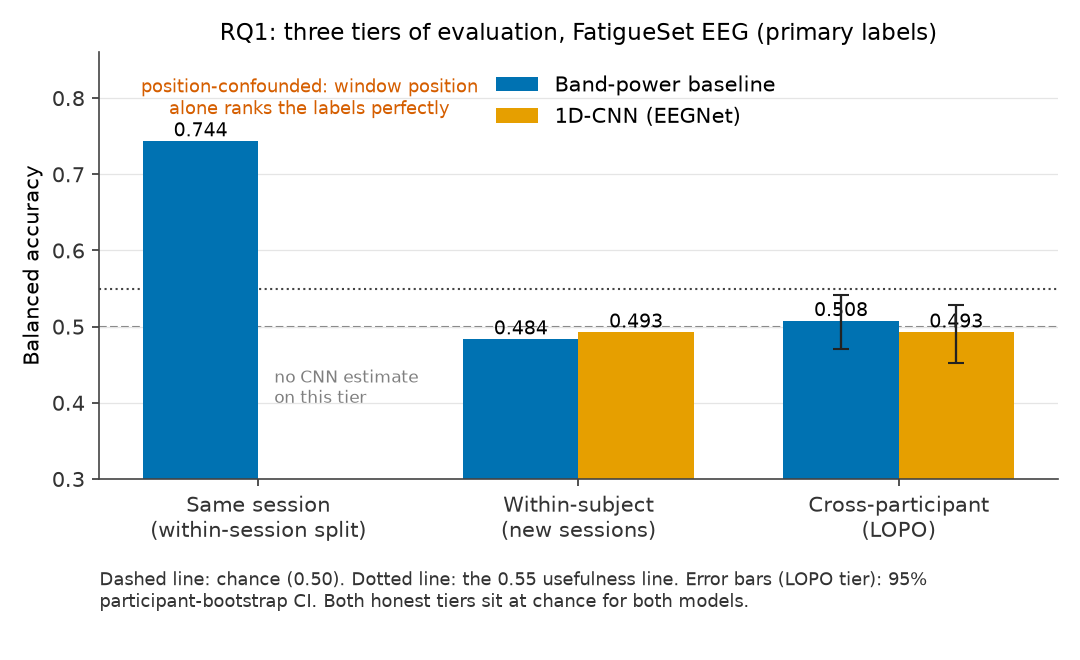

In [6]:
from IPython.display import Image

Image(filename=str(FIG / "fig_rq1_tiers.png"))

## 4. How I read these numbers

- **The within-session estimate (0.744) is not decoding.** Inside one session, window position within the block alone ranks the labels perfectly, and a block permutation null sits at 0.508 with p = 0.612 against the real score. I report 0.744 only as a position-confounded upper bound on separability, never as evidence that the model reads fatigue.
- **The honest tiers are at chance.** Within-subject 0.484, session-out 0.515, LOPO 0.508 [0.471, 0.542]. No feature set I tested transfers above chance to unseen participants, and the EEG features add nothing beyond the mask pattern: a model given only the three masking indicators scores 0.530, about the same as the full 43 features.
- **The null is informative, not a broken pipeline.** The positive control shows the same pipeline recovering an injected effect down to a known minimum size (theta power x1.5, alpha power x1.25), so an effect of that size would have been seen if it transferred.

Full diagnostics: `docs/week2_diagnostics.md`. The decision rules these numbers were read under: `docs/decision_table_lock.md`.